# Generate source-level connectomes from the ProbConn atlas

---

## 🧪 - Experiment setup
- `src`: Source Space
- `tractogram`: Tractogram
- `ctx`: Cortical Mask
- `t12diff`: T1 subject space to Diffusion space transform
- `ras2tkras`: T1 subject space to FreeSurfer space transform

In [ ]:
import mindmap as mm
import numpy as np
import pandas as pd

dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

src = dm.load(sub, "fwd", desc="sim")["src"]
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")
probcon = dm.load_ref("REF_CON")   # check this

## 🧬 - Data Processing

Preprocess atlas.

In [56]:
# convert atlas to binary adjacency matrix
consistency = probcon["matrices"]["consistency"][:,:]
length      = probcon["matrices"]["length"][:,:]
number      = probcon["matrices"]["numbStlines"][:,:]

consistency = np.nan_to_num(consistency)
length      = np.nan_to_num(length)
number      = np.nan_to_num(number)

regions = probcon["header"]["gmcoords"][:]

# Threshold atlas
atlas = np.bitwise_and(
    consistency > 65, 
    length > 0,
)
atlas = np.bitwise_and(
    atlas,
    number > 0,
)
atlas = length * atlas

Upscale connectome from atlas.

In [57]:
import numpy as np
import nibabel as nib
from scipy.spatial.distance import cdist

import mne
from mindmap.anatomy.parcellation import Parcellation

def connectome_from_atlas(
    source_space: mne.SourceSpaces,
    parcellation: Parcellation,
    atlas_matrix: np.ndarray,
    ras2tkras: np.ndarray,
    sparsity: float = 0.2,
    deterministic: bool = True,
    sigma: float = 50.0,
) -> np.ndarray:
    """
    Builds a source-space distance connectome using boundary proximity mapping.

    Parameters
    ----------
    source_space: mne.SourceSpaces
        Source space.

    parcellation: Parcellation
        Parcellation related to atlas.

    atlas_matrix: np.ndarray of shape (m, m)
        Macro connetcome matrix where entries are average fiber lengths.

    ras2tkras: np.ndarray of shape (4,4)
        Affine transform matrix from FreeSurfer to subject RAS.
    
    sparsity: float
        Value between 0.0 and 1.0 dictating the portion of connections to keep per region pair.
    
    deterministic: bool, otpional (default=True)
        If True, connects the absolute closest dipoles.
        If False, uses a distance-weigthed random lottery to spread out connections.

    sigma: float, optional (defautl=50.0)
        The spatial decay constant (in mm) used only when deterministic=False.
        Smaller values force tighter clustering; larger values allow more widespread randomness.
    
    Returns
    -------
    source_connectome: np.ndarray of shape (n_dipoles, n_dipoles)
        High-resolution distance matrix for the source space.
    """
    # 1. Label dipoles according to atlas brain regions
    # get raw dipole positions (n x 3) in millimeters
    dipoles = mm.anatomy.source_space.get_dipole_positions(source_space) * 1000
    n_dipoles = dipoles.shape[0]

    # trasnform dipoles to the parcellation/subject RAS space
    inv_ras2tkras = np.linalg.inv(ras2tkras)
    transformed_dipoles = nib.affines.apply_affine(inv_ras2tkras,dipoles)

    # get region label IDs for all dipoles
    dipole_labels = parcellation.label_points(transformed_dipoles, return_id=True)

    # 2. Initialize the high-resolution connectome matrix
    source_connectome = np.zeros((n_dipoles, n_dipoles))

    # pre-group dipole indices by their region ID to avoid searching inside the loop
    num_regions = atlas_matrix.shape[0]
    global_indices = np.arange(n_dipoles)
    region_to_dipoles = {
        r: global_indices[dipole_labels == (r + 1)]
        for r in range(num_regions)
    }

    # Iterate through unique macro-region pairs
    for i in range(num_regions):
        idx_i = region_to_dipoles[i]
        if len(idx_i) == 0:
            continue

        for j in range(i+1, num_regions):
            idx_j = region_to_dipoles[j]
            if len(idx_j) == 0:
                continue

            # check if an actual white matter tract exists in the atlas
            W_ij = atlas_matrix[i, j]
            if W_ij == 0:
                continue

            # extract 3D coordinates for dipoles in both regions
            coords_i = transformed_dipoles[idx_i]
            coords_j = transformed_dipoles[idx_j]

            # 3. Compute pairwise 3D euclidean distances
            dist_3d_matrix = cdist(coords_i, coords_j, metric="euclidean")

            # find closest boundary distance between these two subsets
            min_3d_dist = np.min(dist_3d_matrix)

            # calibrate distances based on the Atlas average tract length
            tract_dist_matrix = dist_3d_matrix - min_3d_dist + W_ij

            # 4. Apply sparsity constraint
            total_possible_edges = len(idx_i) * len(idx_j)
            k_keep = max(1, int(np.round(total_possible_edges * sparsity)))

            flat_tract_distances = tract_dist_matrix.ravel()
            keep_mask_flat = np.zeros(total_possible_edges, dtype=bool)

            # --- METHOD A: Purely Deterministic (Closest Neighbor) ---
            if deterministic:
                if k_keep < total_possible_edges:
                    threshold_val = np.partition(flat_tract_distances, k_keep - 1)[k_keep - 1]
                    keep_mask_flat = flat_tract_distances <= threshold_val

                    # exact tie-breaker to guarantee exactly k_keep indices
                    if np.sum(keep_mask_flat) > k_keep:
                        true_indices = np.where(keep_mask_flat)[0]
                        keep_mask_flat[true_indices[k_keep:]] = False
                else:
                    keep_mask_flat = np.ones(total_possible_edges, dtype=bool)

            # --- METHOD B: Stochastic (Distance-Weighted Lottery) ---
            else:
                if k_keep < total_possible_edges:
                    # Map distances to weights using exponential decay
                    # subtracting min ensures numerical stability (prevents underflow).
                    weights = np.exp(-(flat_tract_distances - np.min(flat_tract_distances)) / sigma)

                    # Normalize weights into a true probability distribution summing to 1
                    probabilities = weights / np.sum(weights)

                    # sample k_keep unique edge indices without replacement
                    chosen_indices = np.random.choice(
                        total_possible_edges,
                        size = k_keep,
                        replace = False,
                        p = probabilities,
                    )
                    keep_mask_flat[chosen_indices] = True
                else:
                    keep_mask = keep_mask_flat = np.ones(total_possible_edges, dtype=bool)

            # Reshape the flat mask to the 2D sub-matrix shape
            keep_mask = keep_mask_flat.reshape(tract_dist_matrix.shape)

            # 5. Map back to gloabl source connectome coordinates
            # Get the local row/column positions where mask is True
            row_indices, col_indices = np.where(keep_mask)

            # Translate local sub-matrix indices back to global source-space indices
            global_row = idx_i[row_indices]
            global_col = idx_j[col_indices]

            # Get the distances for those chosen pairs 
            final_distances = tract_dist_matrix[keep_mask]

            # Symmetrically assign to the master matrix
            source_connectome[global_row, global_col] = final_distances
            source_connectome[global_col, global_row] = final_distances

    return source_connectome


In [58]:
# connectivity of white matter tracts
con_wm = connectome_from_atlas(
    src,
    parc,
    atlas,
    ras2tkras,
    sparsity = 0.01,
    deterministic = True,
)

# connectivity of gray matter tracts
con_gm = mm.analysis.connectivity.connectome_from_geometry(
    src,
    maximum_dist = 15,
    maximum_neigh = 3,
    weights = True,
)

# fuse connectomes
con = con_wm.copy()
gm_idx = np.argwhere(con_gm > 0)
con[gm_idx[:,0], gm_idx[:,1]] = con_gm[gm_idx[:,0], gm_idx[:,1]]

## 📊 - Visualization
Atlas structural connectome.

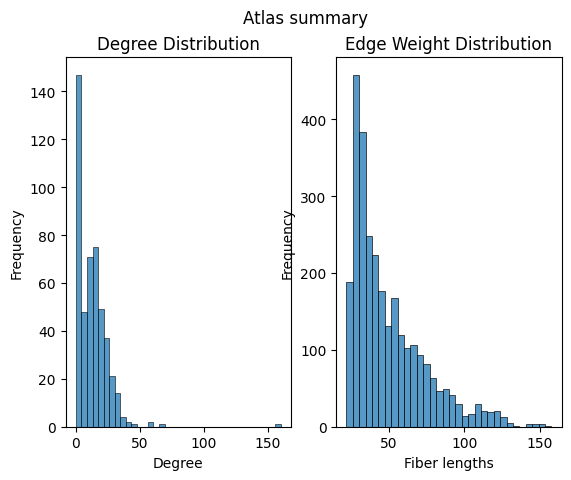

In [59]:
mm.viz.plot_con_summary(atlas, title = "Atlas summary", xlabel="Fiber lengths")

Atlas adjacency matrix.

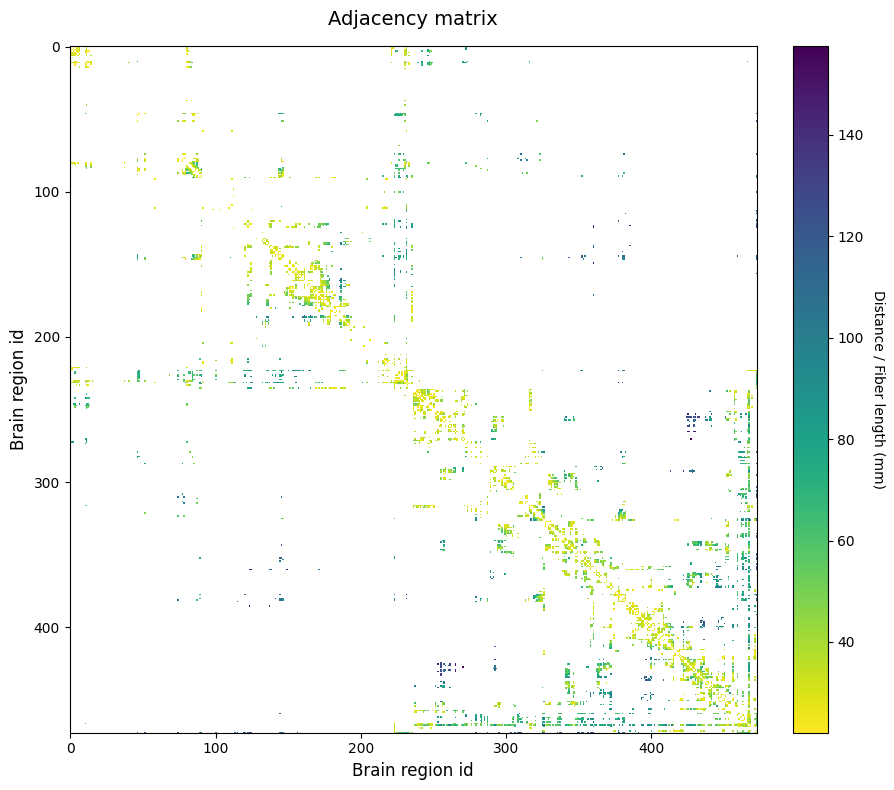

In [60]:
mm.viz.plot_adj_matrix(atlas, clabel="Distance / Fiber length (mm)", xylabel = "Brain region id")

Upscaled connectome summary.

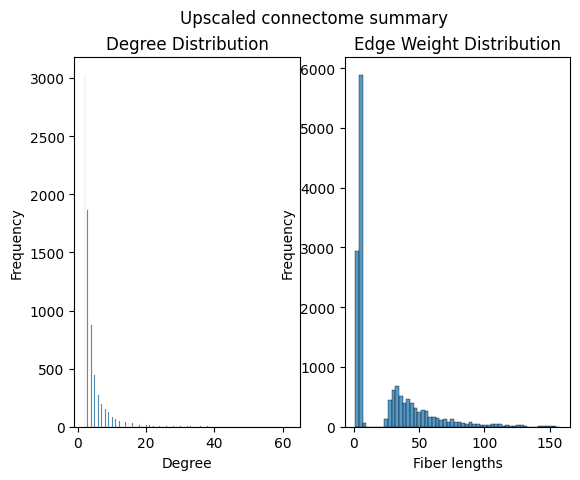

In [61]:
mm.viz.plot_con_summary(con, title = "Upscaled connectome summary", xlabel="Fiber lengths")

Upscaled connectome connectivity matrix.

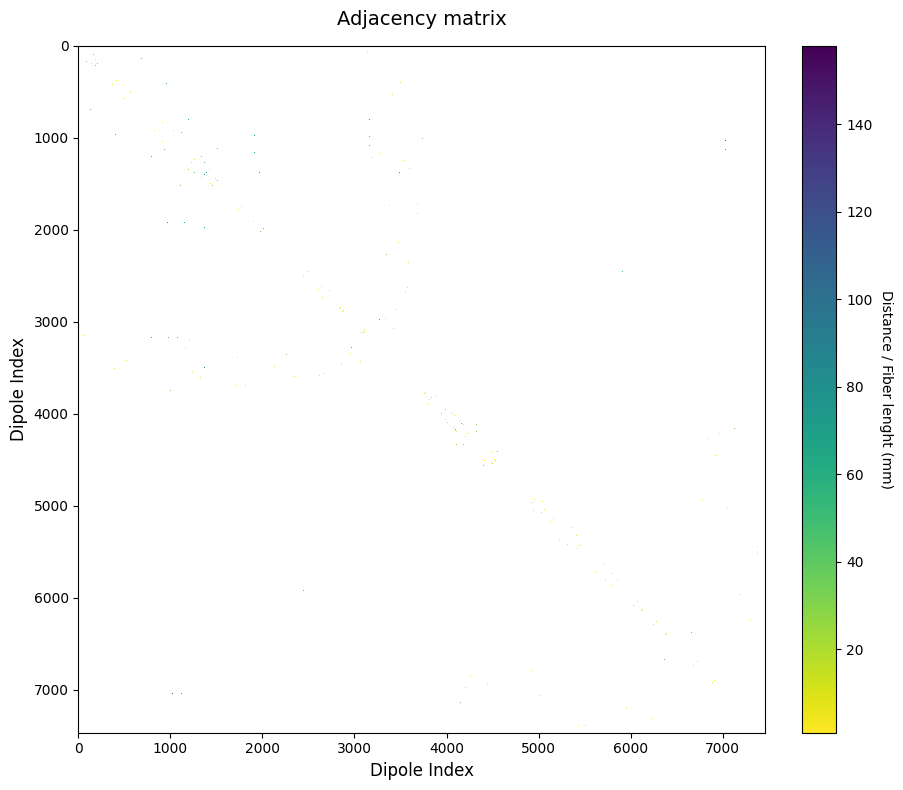

In [63]:
con_viz, _ = mm.analysis.connectivity.order_connectome_by_region(con, src, parc, ras2tkras)
mm.viz.plot_adj_matrix(con_viz, clabel="Distance / Fiber lenght (mm)")


Isolated nodes.

In [66]:
# Visualize isolated nodes
isolated_nodes = np.argwhere(np.sum(con>0, axis=1)==0).squeeze()
targets = np.zeros(mm.anatomy.source_space.get_ndipole(src))
targets[isolated_nodes] = 1

print(f"Number of isolated nodes: {int(targets.sum())}")
mm.viz.plot_brain(src, targets).show()

Number of isolated nodes: 0


Widget(value='<iframe src="http://localhost:36277/index.html?ui=P_0x747b4e067e10_0&reconnect=auto" class="pyvi…